# assignment 2 code stuff
## part 1: stochastic models
### make sure that we use same N = [1000, 5000, 10000] and same SEED = 42 for both docs
###to do: rerun with 1000, 10000, 100000 to make it more interesting 

save all data as csv files and upload to git

Write Python code in a Jupyter Notebook to implement Gillespies Algorithm (GA) 1 . You should define the events and the rates of each event for the SIR model. Keep in mind it may be insightful to compare the GA stochastic simulation with an equivalent deterministic ODE model. BONUS: You can also think about (and implement) a way to control the noise level in the GA.

In [2]:
#install packages
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import fftpack
from scipy.optimize import minimize
import math
from itertools import product

#set seed
SEED = 42
np.random.seed(SEED)

## make data for GA and deterministic SIR

Text(0, 0.5, 'I(t)')

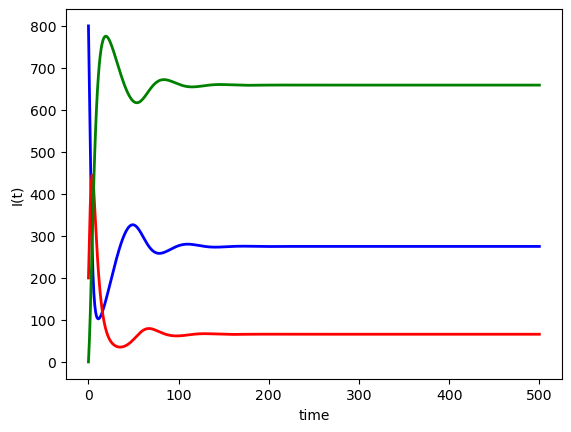

In [ ]:
#make normal deterministic SIR for baseline
#return SIR not dsdt etc to make it comparable for the models?
# N is no longer constant so we use XYZ and frequency dep formulation to keep comparable
###

def deterministic_SIR(state, t, beta, gamma, mu):
    N = sum(state)
    X, Y, Z = state

    dX =  mu*N - (beta * X * Y * 1/N) - mu * X
    dY =  (beta * X * Y * 1/N) - (gamma * Y) - mu *Y
    dZ =  gamma * Y - mu * Z
    return [dX, dY, dZ]


state0 = [800, 200, 0] # SIR
t = np.linspace(0, 500, 501)
# solve ODE
beta = 0.8
gamma = 0.2
mu = 0.02
state1 = odeint(deterministic_SIR,state0,t, args = (beta, gamma,mu, ))
X1 = [state1[i][0] for i in range(0, len(state1))]
Y1 = [state1[i][1] for i in range(0, len(state1))]
Z1 = [state1[i][2] for i in range(0, len(state1))]

plt.plot(t,X1,'b-',linewidth=2,label="S(t)")
plt.plot(t,Y1,'r-',linewidth=2,label="I(t)")
plt.plot(t,Z1,'g-',linewidth=2,label="R(t)")
plt.xlabel('time')
plt.ylabel('I(t)')

In [ ]:
### to do: kepp these params constant across experiments, are these the ones we want?
# Parameter values
N_values = [1000, 5000, 10000]
beta_values = [0.8, 0.6, 0.4]
gamma_values = [0.6, 0.4]

# Fixed parameters
I0 = 5
R_init = 0
mu = 0.02

# Time points
t = np.linspace(0, 500, 501)

In [ ]:

#make baseline data with det sir model
#same N values for all exp, initial infection with I=5, try different beta and gamma vals 


# Store all simulation results
all_results = []

# Run every combination of N, beta, and gamma
for N, beta, gamma in product(
    N_values, beta_values, gamma_values
):
    # Initial conditions: infected count always equals 5
    S0 = N - I0 - R_init
    state0 = [S0, I0, R_init]

    # Solve the ODE
    state = odeint(deterministic_SIR,state0,t,args=(beta, gamma, mu))

    # Save results for this parameter combination
    df = pd.DataFrame({
        "N": N,
        "beta": beta,
        "gamma": gamma,
        "mu": mu,
        "time": t,
        "S": state[:, 0],
        "I": state[:, 1],
        "R": state[:, 2]
    })

    all_results.append(df)

# Combine all simulations into one DataFrame
results_df = pd.concat(all_results, ignore_index=True)

# Export to CSV
results_df.to_csv("deterministic_SIR_results.csv",index=False)

print("All simulations completed.")
print(f"Number of parameter combinations: {len(N_values) * len(beta_values) * len(gamma_values)}")
print(f"Total number of rows: {len(results_df)}")
print(results_df.head())


All simulations completed.
Number of parameter combinations: 18
Total number of rows: 9018
      N  beta  gamma    mu  time           S         I          R
0  1000   0.8    0.6  0.02   0.0  995.000000  5.000000   0.000000
1  1000   0.8    0.6  0.02   1.0  990.800829  5.952444   3.246728
2  1000   0.8    0.6  0.02   2.0  985.898817  7.060613   7.040570
3  1000   0.8    0.6  0.02   3.0  980.192497  8.339685  11.467818
4  1000   0.8    0.6  0.02   4.0  973.576554  9.802106  16.621340


In [25]:
print(np.log(0.1)*1)

-2.3025850929940455


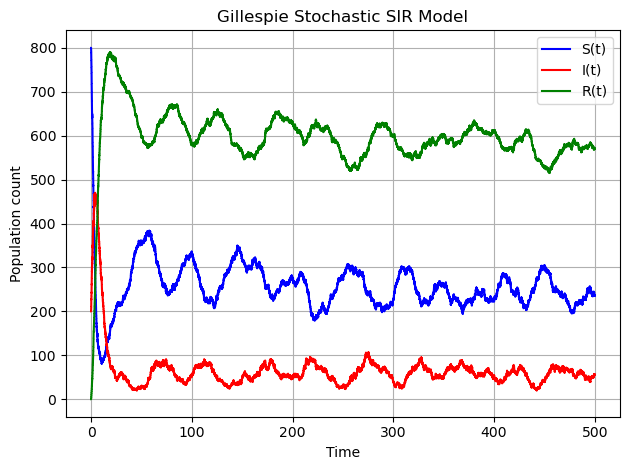

In [28]:
###make gillespie model
#define events outside of model
#define rates in model

#define events 
keys = ['infection', 'recovery', 'birth', "death_X", "death_Y", "death_Z"]


# Initial conditions: susceptible, infected, recovered
state0 = [800, 200, 0]

# Simulation settings
t = np.linspace(0, 500, 501)
beta = 0.8
gamma = 0.2
mu = 0.02
noise = 1 #parameter to control noise, set to 0 if you

# Define events
keys = [ "infection", "recovery", "birth", "death_X", "death_Y", "death_Z"]


def GA(state0, t, keys, beta, gamma, mu, noise):
    X, Y, Z = state0
    current_time = t[0]

    # Store simulation results
    times = [current_time]
    X_values = [X]
    Y_values = [Y]
    Z_values = [Z]

    while current_time < t[-1]:

        # Total population
        N = X + Y + Z

        if N == 0:
            break

        # Calculate event rates
        values = [
            beta * X * Y / N,  # Infection
            gamma * Y,         # Recovery
            mu * N,            # Birth
            mu * X,            # Death of X
            mu * Y,            # Death of Y
            mu * Z             # Death of Z
        ]

        rates = dict(zip(keys, values))

        # Calculate waiting time for each event like instructions in the slides
        waiting_times = {}

        for key, rate in rates.items():
            if rate > 0:
                U = np.random.uniform(0, 1) * noise
                #multiply U by factor f or scaled factor f to control noise level? f=0-> effectively no
                waiting_times[key] = (-1/rate) * (np.log(U) * noise) 
                #i want that that ln(u) to be closer to 1 if "noise" param is low
            else:
                waiting_times[key] = np.inf

        # Find the event with the shortest waiting time
        key = min(waiting_times, key=waiting_times.get)
        dt = waiting_times[key]

        # Stop if the event occurs beyond the simulation horizon
        if current_time + dt > t[-1]:
            break

        # Update time
        current_time += dt

        # Implement the selected event
        if key == "infection":
            X -= 1
            Y += 1

        elif key == "recovery":
            Y -= 1
            Z += 1

        elif key == "birth":
            X += 1

        elif key == "death_X":
            X -= 1

        elif key == "death_Y":
            Y -= 1

        elif key == "death_Z":
            Z -= 1

        # Store the updated population
        times.append(current_time)
        X_values.append(X)
        Y_values.append(Y)
        Z_values.append(Z)

    return times, X_values, Y_values, Z_values


# Run the simulation
times, X1, Y1, Z1 = GA(state0, t, keys, beta, gamma, mu, noise)

# Plot the results
plt.step(times, X1, where="post", color="blue", label="S(t)")
plt.step(times, Y1, where="post", color="red", label="I(t)")
plt.step(times, Z1, where="post", color="green", label="R(t)")

plt.xlabel("Time")
plt.ylabel("Population count")
plt.title("Gillespie Stochastic SIR Model")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [29]:
#make ga data
noise_values = [1]
###to do: think about how to implement noise instead

mu = 0.02
I0 = 5
R0 = 0
n_repeats = 5 #is this enough?

all_results = []

for N0, beta, gamma, noise in product(
    N_values, beta_values, gamma_values, noise_values
):
    state0 = [N0 - I0 - R0, I0, R0]

    for repeat in range(1, n_repeats + 1):
        times, S, I, R = GA(state0, t, keys, beta, gamma, mu, noise)
        # Gillespie output is event-based.
        # Record the state at each observation time.
        obs_indices = np.searchsorted(
            times, t, side="right"
        ) - 1

        # Initial state is always recorded at t[0]
        obs_indices = np.maximum(obs_indices, 0)

        df = pd.DataFrame({
            "N": N0,
            "beta": beta,
            "gamma": gamma,
            "mu": mu,
            "noise": noise,
            "repeat": repeat,
            "time": t,
            "S": np.array(S)[obs_indices],
            "I": np.array(I)[obs_indices],
            "R": np.array(R)[obs_indices]
        })

        all_results.append(df)

# Combine and save
results_df = pd.concat(all_results, ignore_index=True)

results_df.to_csv(
    "Gillespie_SIR_results.csv",
    index=False
)

print("Simulations completed.")
print("Number of simulations:", len(all_results))
print("Number of rows:", len(results_df))
print(results_df.head())
    

Simulations completed.
Number of simulations: 90
Number of rows: 45090
      N  beta  gamma    mu  noise  repeat  time    S   I   R
0  1000   0.8    0.6  0.02      1       1   0.0  995   5   0
1  1000   0.8    0.6  0.02      1       1   1.0  981   7   5
2  1000   0.8    0.6  0.02      1       1   2.0  975   5  10
3  1000   0.8    0.6  0.02      1       1   3.0  956  10  17
4  1000   0.8    0.6  0.02      1       1   4.0  948  12  21


investigate how varying the model parameters changes the behaviour of the stochastic dynamics, in particular how they relate to variance between runs and how they impact negative covariance between S and I. 
Compare the mean of the stochastic simulations with the equivalent deterministic model output (do this for multiple settings of the model parameters)


In [30]:

#do i still need this? current version keeps vals for the same t timeframe always
def evaluate_gillespie(time_grid, run_df, column):
    #get ga results on the same timeframe as the det sir
    #while respecting that ga is a step function, so vals only change during event
    run_df = run_df.sort_values("time")
    event_times = run_df["time"].to_numpy()
    values = run_df[column].to_numpy()

    indices = np.searchsorted(
        event_times, time_grid, side="right"
    ) - 1

    result = np.zeros(len(time_grid))
    valid = indices >= 0
    result[valid] = values[indices[valid]]

    return result



## analyse data from GA and deterministic SIR

In [32]:
#get data in dataset if you dont want to rerun ^^
if "df_ga" not in globals():
    df_ga = pd.read_csv("Gillespie_SIR_results.csv")
if "df_det_sir" not in globals():
    df_det_sir = pd.read_csv("deterministic_SIR_results.csv")

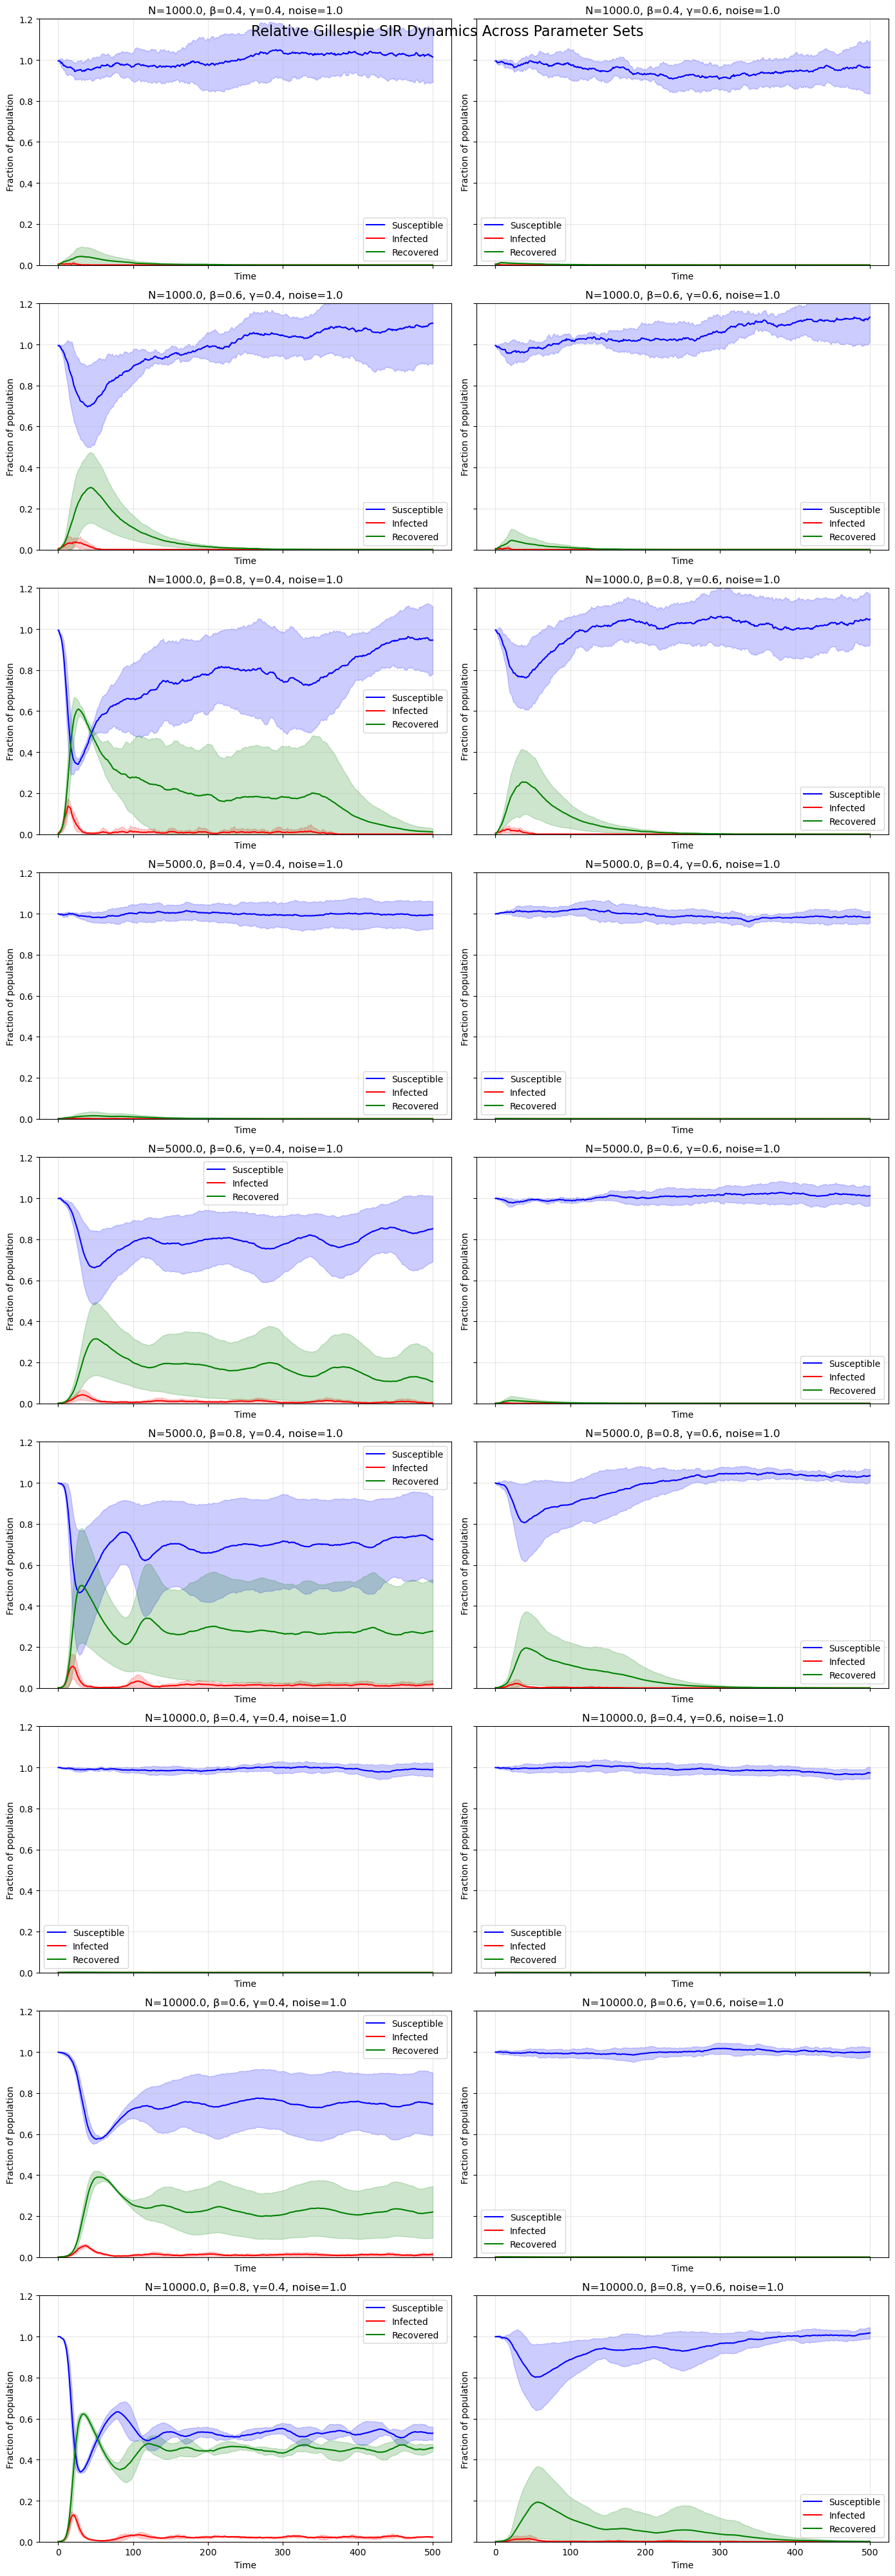

In [34]:
#show what sir dynamics look like for different param sets
#include +-sd
#det version as baseline?

parameter_cols = ["N", "beta", "gamma", "noise"]

parameter_sets = (
    df_ga[parameter_cols]
    .drop_duplicates()
    .sort_values(parameter_cols)
    .reset_index(drop=True)
)

n_params = len(parameter_sets)
ncols = 2
nrows = math.ceil(n_params / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(7 * ncols, 4.5 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

colors = {
    "S": "blue",
    "I": "red",
    "R": "green"
}

labels = {
    "S": "Susceptible",
    "I": "Infected",
    "R": "Recovered"
}

for idx, params in parameter_sets.iterrows():

    ax = axes[idx]

    mask = np.ones(len(df_ga), dtype=bool)
    for col in parameter_cols:
        mask &= df_ga[col].eq(params[col]).to_numpy()

    subset = df_ga.loc[mask]
    N = params["N"]

    for compartment in ["S", "I", "R"]:

        trajectories = subset.pivot(
            index="repeat",
            columns="time",
            values=compartment
        ).sort_index(axis=1)

        time_grid = trajectories.columns.to_numpy()

        # Normalize each trajectory by the total population N
        values = trajectories.to_numpy() / N

        mean = np.mean(values, axis=0)

        if len(values) > 1:
            sd = np.std(values, axis=0, ddof=1)
        else:
            sd = np.zeros_like(mean)

        ax.plot(
            time_grid,
            mean,
            color=colors[compartment],
            label=labels[compartment]
        )

        ax.fill_between(
            time_grid,
            mean - sd,
            mean + sd,
            color=colors[compartment],
            alpha=0.2
        )

    ax.set_title(
        f"N={N}, β={params['beta']}, "
        f"γ={params['gamma']}, noise={params['noise']}"
    )
    ax.set_xlabel("Time")
    ax.set_ylabel("Fraction of population")
    ax.set_ylim(0, 1.2)
    ax.grid(True, alpha=0.3)
    ax.legend()

for idx in range(n_params, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle(
    "Relative Gillespie SIR Dynamics Across Parameter Sets",
    fontsize=16
)

plt.tight_layout()
plt.show()


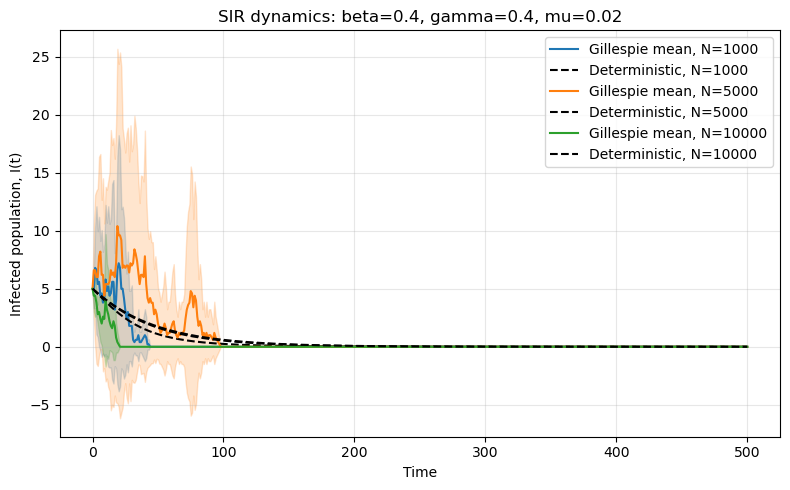

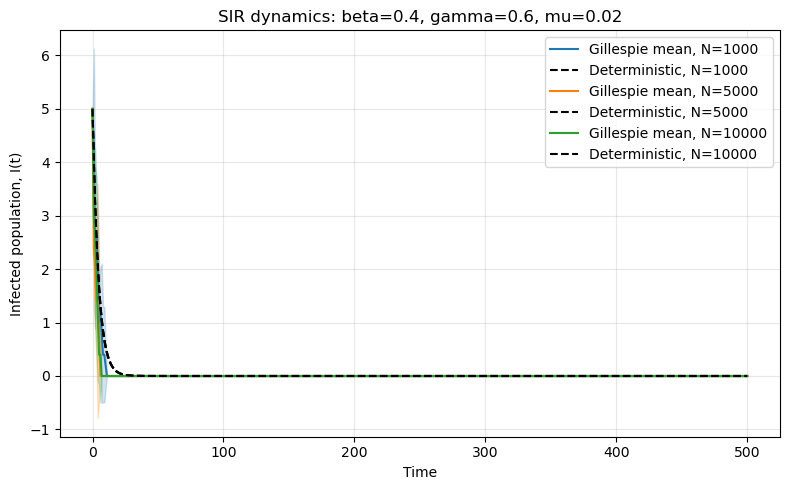

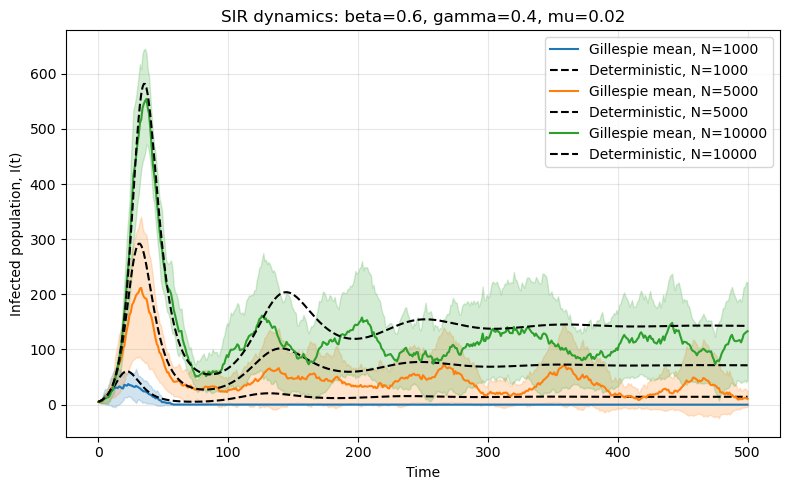

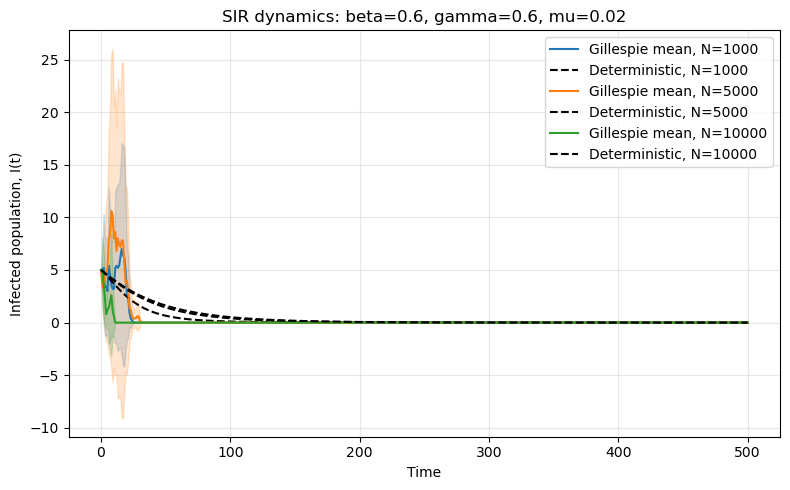

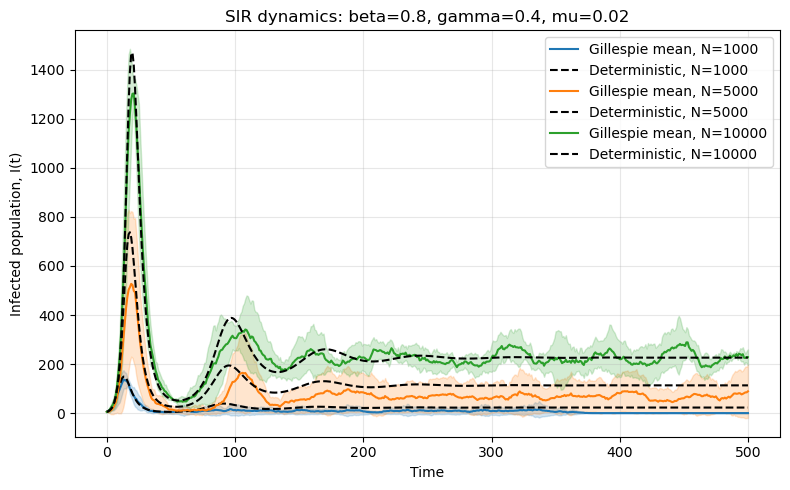

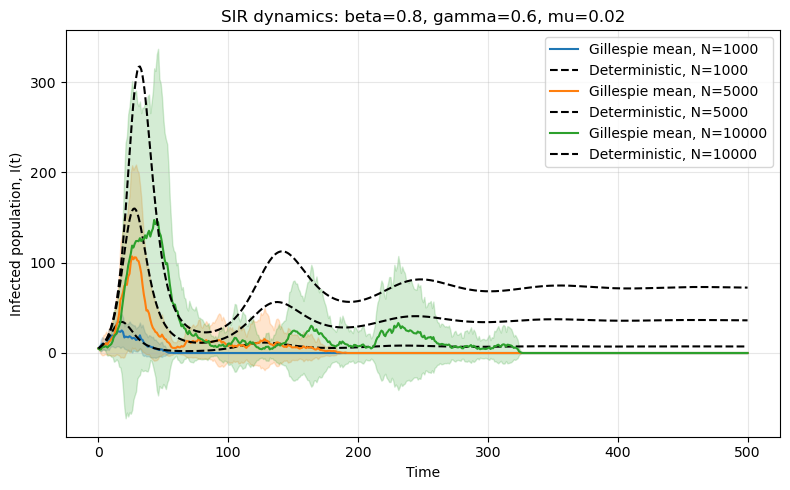

In [ ]:
#look at how I(t) develops
###to do: make less ugly
# Group by parameters other than N, so different N values
# are plotted together
parameter_cols = ["beta", "gamma", "mu"]

for params, subset_params in df_ga.groupby(parameter_cols):

    beta_value, gamma_value, mu_value = params

    plt.figure(figsize=(8, 5))

    # Plot each population size N in this parameter combination
    for N_value, subset_N in subset_params.groupby("N"):

        # --- Gillespie stochastic results ---
        I_runs = []

        for replicate, run_df in subset_N.groupby("repeat"):
            I_runs.append(
                evaluate_gillespie(t, run_df, "I")
            )

        I_runs = np.asarray(I_runs)

        I_mean = np.mean(I_runs, axis=0)

        if len(I_runs) > 1:
            I_sd = np.std(I_runs, axis=0, ddof=1)
        else:
            I_sd = np.zeros_like(I_mean)

        # --- Deterministic baseline ---
        # Match beta, gamma, mu AND N
        subset_det = df_det_sir[
            (df_det_sir["beta"] == beta_value) &
            (df_det_sir["gamma"] == gamma_value) &
            (df_det_sir["mu"] == mu_value) &
            (df_det_sir["N"] == N_value)
        ].sort_values("time")

        # Plot Gillespie mean and SD
        line, = plt.plot(
            t, I_mean,
            label=f"Gillespie mean, N={N_value}"
        )

        plt.fill_between(
            t,
            I_mean - I_sd,
            I_mean + I_sd,
            color=line.get_color(),
            alpha=0.2
        )

        # Plot deterministic baseline in black
        if not subset_det.empty:
            I_det = np.interp(
                t,
                subset_det["time"].to_numpy(),
                subset_det["I"].to_numpy()
            )

            plt.plot(
                t,
                I_det,
                color="black",
                linestyle="--",
                linewidth=1.5,
                label=f"Deterministic, N={N_value}"
            )
        else:
            print(
                f"No deterministic data for N={N_value}, "
                f"beta={beta_value}, gamma={gamma_value}, "
                f"mu={mu_value}"
            )

    plt.xlabel("Time")
    plt.ylabel("Infected population, I(t)")
    plt.title(
        f"SIR dynamics: beta={beta_value}, "
        f"gamma={gamma_value}, mu={mu_value}"
    )
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


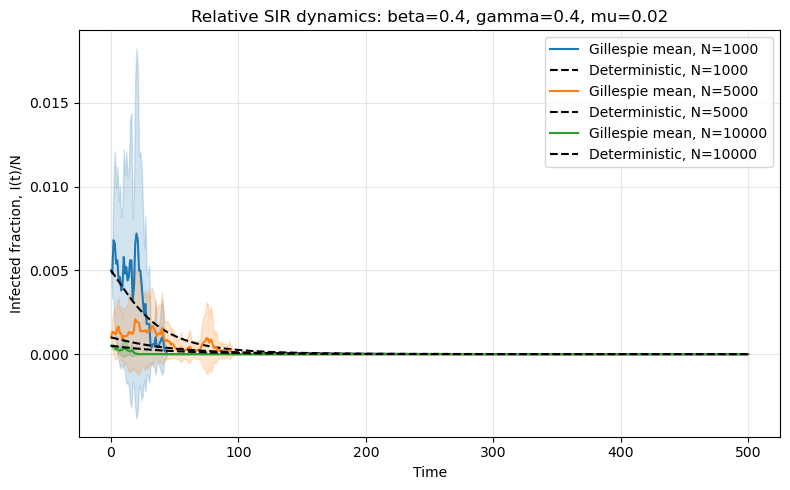

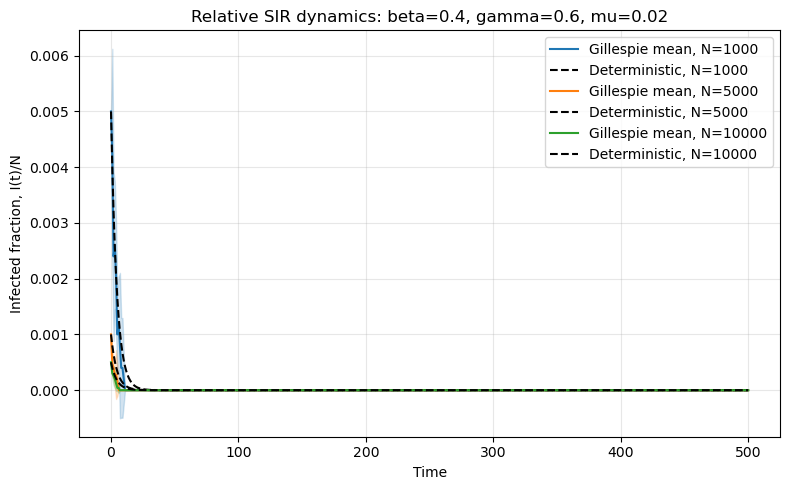

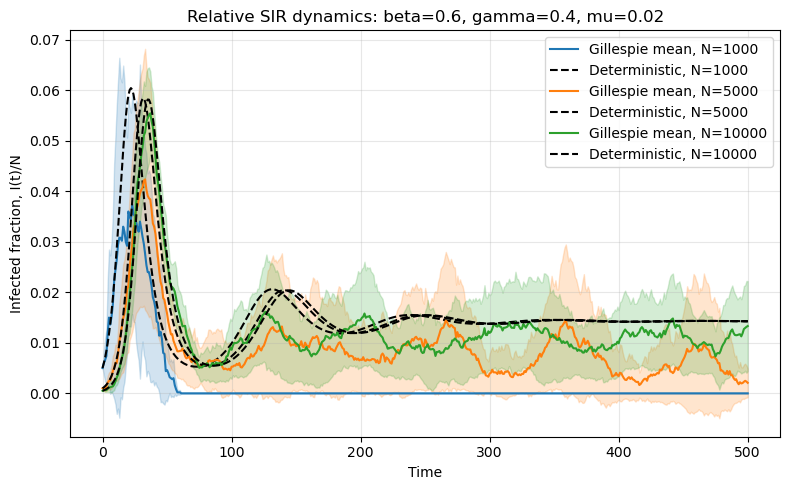

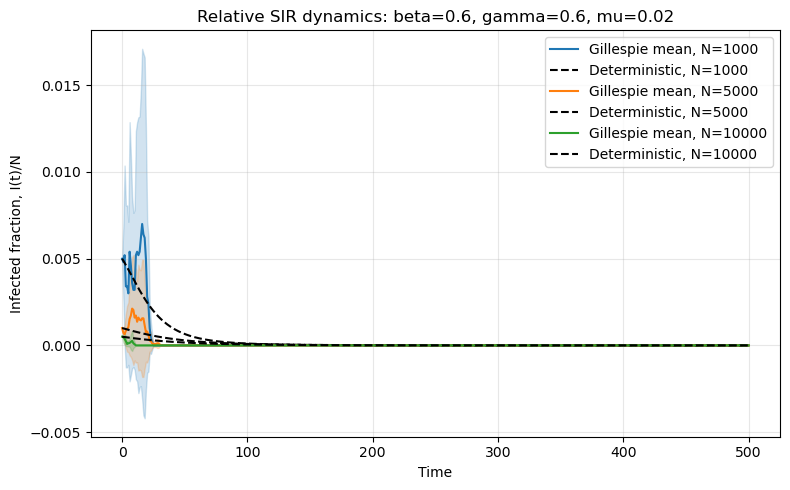

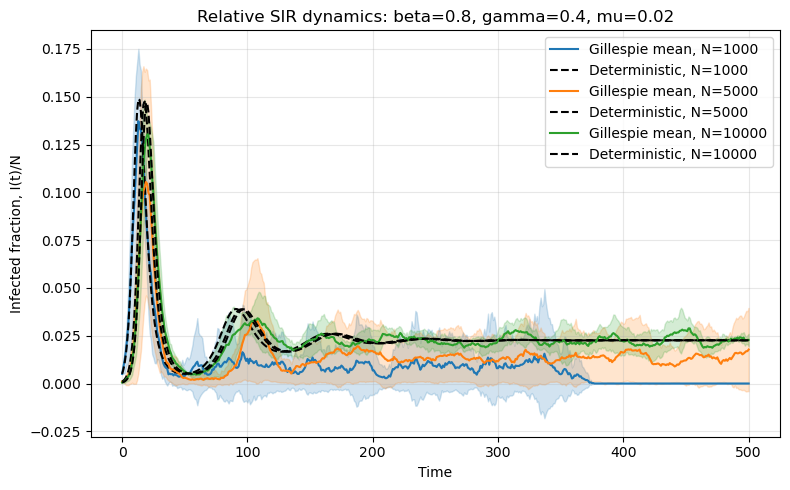

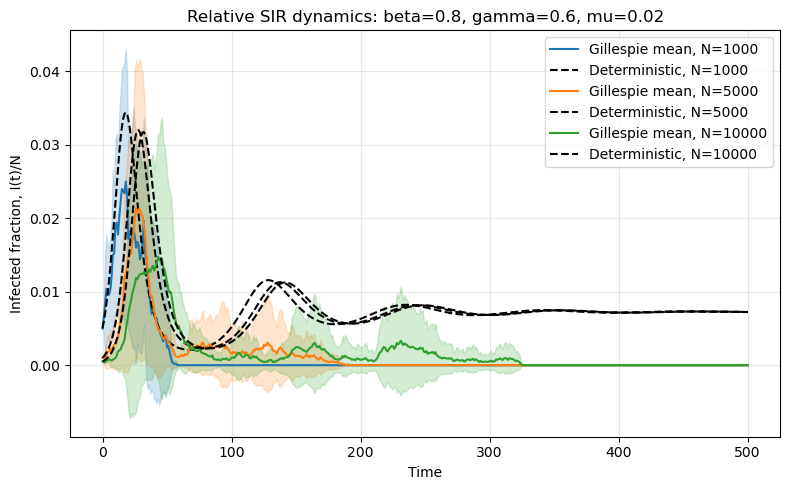

In [36]:

#normalized I(t) instead

# Group by parameters other than N
parameter_cols = ["beta", "gamma", "mu"]

for params, subset_params in df_ga.groupby(parameter_cols):

    beta_value, gamma_value, mu_value = params

    plt.figure(figsize=(8, 5))

    # Plot each population size N in the same figure
    for N_value, subset_N in subset_params.groupby("N"):

        # --- Gillespie stochastic results ---
        I_runs = []

        for repeat, run_df in subset_N.groupby("repeat"):
            I_runs.append(
                evaluate_gillespie(t, run_df, "I")
            )

        I_runs = np.asarray(I_runs)

        # Normalize each trajectory by population size N
        I_runs = I_runs / N_value

        I_mean = np.mean(I_runs, axis=0)

        if len(I_runs) > 1:
            I_sd = np.std(I_runs, axis=0, ddof=1)
        else:
            I_sd = np.zeros_like(I_mean)

        # --- Deterministic baseline ---
        subset_det = df_det_sir[
            (df_det_sir["beta"] == beta_value) &
            (df_det_sir["gamma"] == gamma_value) &
            (df_det_sir["mu"] == mu_value) &
            (df_det_sir["N"] == N_value)
        ].sort_values("time")

        # Gillespie mean infected fraction
        line, = plt.plot(
            t,
            I_mean,
            label=f"Gillespie mean, N={N_value}"
        )

        # Standard deviation across replicates
        plt.fill_between(
            t,
            I_mean - I_sd,
            I_mean + I_sd,
            color=line.get_color(),
            alpha=0.2
        )

        # Deterministic infected fraction, plotted in black
        if not subset_det.empty:
            I_det = np.interp(
                t,
                subset_det["time"].to_numpy(),
                subset_det["I"].to_numpy()
            )

            I_det = I_det / N_value

            plt.plot(
                t,
                I_det,
                color="black",
                linestyle="--",
                linewidth=1.5,
                label=f"Deterministic, N={N_value}"
            )
        else:
            print(
                f"No deterministic data for N={N_value}, "
                f"beta={beta_value}, gamma={gamma_value}, "
                f"mu={mu_value}"
            )

    plt.xlabel("Time")
    plt.ylabel("Infected fraction, I(t)/N")
    plt.title(
        f"Relative SIR dynamics: beta={beta_value}, "
        f"gamma={gamma_value}, mu={mu_value}"
    )
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


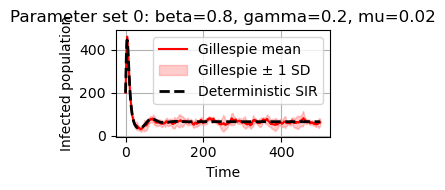

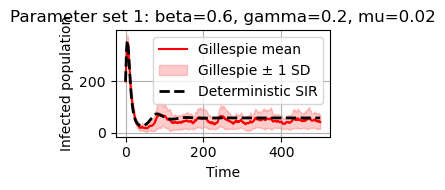

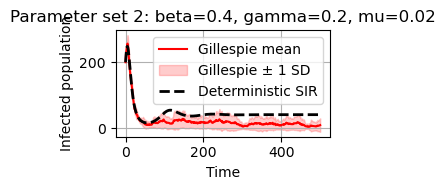

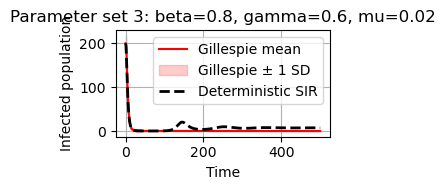

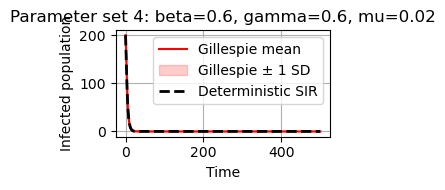

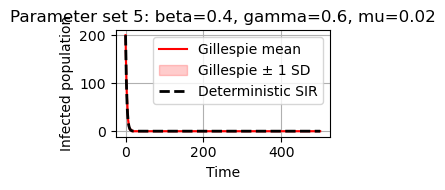

In [ ]:
###old code but the plots are prettier

# One figure per parameter combination
for parameter_id, subset_ga in df_ga.groupby("parameter_id"):

    # --- Gillespie stochastic results ---
    I_runs = []

    for replicate, run_df in subset_ga.groupby("replicate"):
        I_runs.append(
            evaluate_gillespie(t, run_df, "I")
        )

    I_mean = np.mean(I_runs, axis=0)

    # Use sample SD if there is more than one replicate
    if len(I_runs) > 1:
        I_sd = np.std(I_runs, axis=0, ddof=1)
    else:
        I_sd = np.zeros_like(I_mean)

    # --- Deterministic results for the same conditions ---
    subset_det = df_det_sir[
        df_det_sir["parameter_id"] == parameter_id
    ].sort_values("time")

    if subset_det.empty:
        print(f"No deterministic data for parameter_id={parameter_id}")
        continue

    # Interpolate deterministic I values onto the common time grid
    I_det = np.interp(
        t,
        subset_det["time"],
        subset_det["I"]
    )

    # Parameter values for the title
    beta_value = subset_ga["beta"].iloc[0]
    gamma_value = subset_ga["gamma"].iloc[0]
    mu_value = subset_ga["mu"].iloc[0]

    # --- Plot ---
    plt.figure(figsize=(3, 2))

    plt.plot(
        t, I_mean,
        color="red",
        label="Gillespie mean"
    )

    plt.fill_between(
        t,
        I_mean - I_sd,
        I_mean + I_sd,
        color="red",
        alpha=0.2,
        label="Gillespie ± 1 SD"
    )

    plt.plot(
        t, I_det,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Deterministic SIR"
    )

    plt.xlabel("Time")
    plt.ylabel("Infected population")
    plt.title(
        f"Parameter set {parameter_id}: "
        f"beta={beta_value}, gamma={gamma_value}, mu={mu_value}"
    )
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


it seems like the effect is the most visible if the R0 is closest to 1, the infection dies out more easily/quicker/mean i value is lower in stoch compared to det model

###to do: check for models that show strongest oscillation -> find tochastic resonance
###to do repeat this dataset with different n values 

In [38]:

#covariance between s and i averaged OVER TIME, one val per run
covariance_results = []

# Each unique parameter combination and repeat is one run
group_cols = ["N", "beta", "gamma", "mu", "noise", "repeat"]

for group_values, run_df in df_ga.groupby(group_cols):

    run_df = run_df.sort_values("time")

    N, beta, gamma, mu, noise, repeat = group_values

    # Normalize population counts by N
    S_rel = run_df["S"].to_numpy() / N
    I_rel = run_df["I"].to_numpy() / N

    # Covariance across time within this run
    cov_SI = np.cov(S_rel, I_rel, ddof=1)[0, 1]

    covariance_results.append({
        "N": N,
        "beta": beta,
        "gamma": gamma,
        "mu": mu,
        "noise": noise,
        "repeat": repeat,
        "cov_SI": cov_SI
    })

covariance_df = pd.DataFrame(covariance_results)

print(covariance_df.head())


      N  beta  gamma    mu  noise  repeat        cov_SI
0  1000   0.4    0.4  0.02      1       1  3.439681e-06
1  1000   0.4    0.4  0.02      1       2 -1.774117e-05
2  1000   0.4    0.4  0.02      1       3  9.468543e-07
3  1000   0.4    0.4  0.02      1       4 -5.264910e-06
4  1000   0.4    0.4  0.02      1       5 -5.198259e-05


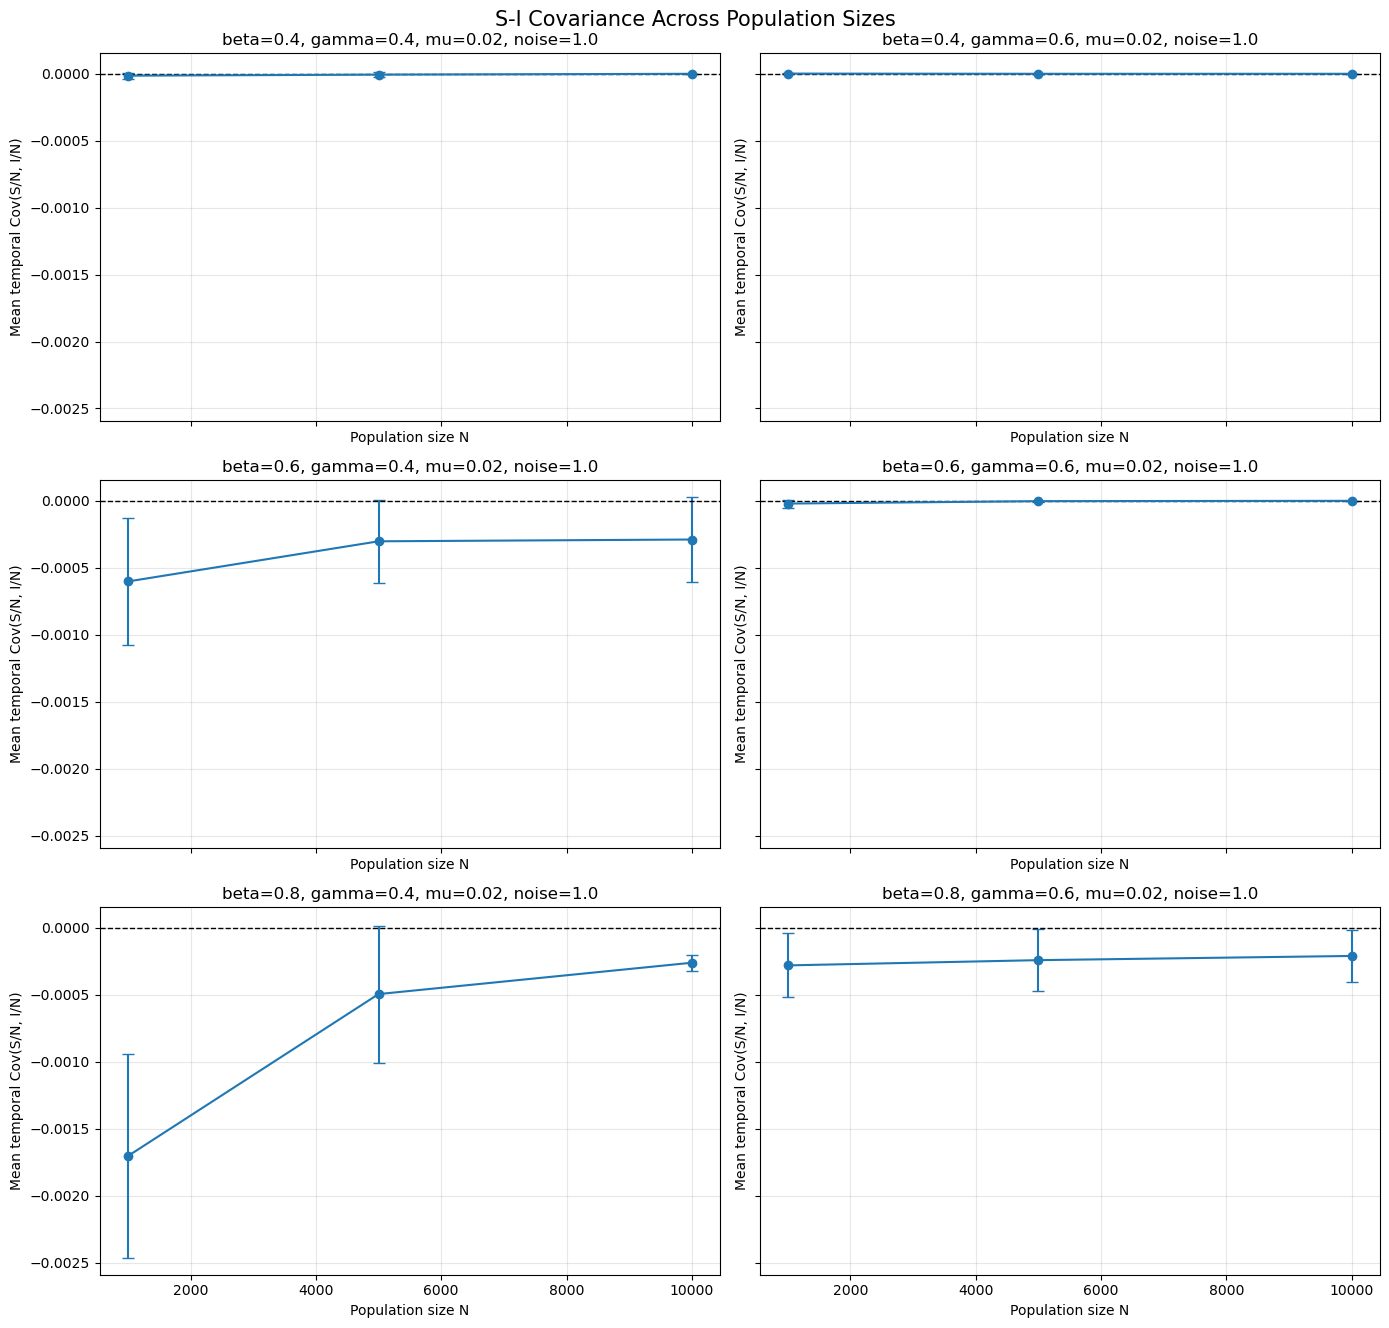

In [ ]:
#plot covariance over N values per param set

parameter_cols = ["beta", "gamma", "mu", "noise"]

# Mean and SD of per-run covariance across repeats
summary = (
    covariance_df
    .groupby(parameter_cols + ["N"])["cov_SI"]
    .agg(["mean", "std"])
    .reset_index()
)

parameter_sets = (
    summary[parameter_cols]
    .drop_duplicates()
    .reset_index(drop=True)
)

n_params = len(parameter_sets)
ncols = 2
nrows = math.ceil(n_params / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(7 * ncols, 4.5 * nrows),
    sharex=True,
    sharey=True,  # Same y-axis scale for all subplots
    squeeze=False
)

axes = axes.flatten()

axes = axes.flatten()

for idx, params in parameter_sets.iterrows():

    ax = axes[idx]

    mask = np.ones(len(summary), dtype=bool)
    for col in parameter_cols:
        mask &= summary[col].eq(params[col]).to_numpy()

    subset = summary.loc[mask].sort_values("N")

    ax.errorbar(
        subset["N"],
        subset["mean"],
        yerr=subset["std"].fillna(0),
        fmt="o-",
        capsize=4
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_xlabel("Population size N")
    ax.set_ylabel("Mean temporal Cov(S/N, I/N)")
    ax.set_title(
        f"beta={params['beta']}, gamma={params['gamma']}, "
        f"mu={params['mu']}, noise={params['noise']}"
    )
    ax.grid(True, alpha=0.3)

for idx in range(n_params, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle("S-I Covariance Across Population Sizes", fontsize=15)
# Apply identical y-axis limits to all subplots
all_means = summary["mean"].to_numpy()
all_sds = summary["std"].fillna(0).to_numpy()

y_min = np.min(all_means - all_sds)
y_max = np.max(all_means + all_sds)

# Add a small margin
margin = 0.05 * (y_max - y_min) if y_max > y_min else 0.01

for ax in axes[:n_params]:
    ax.set_ylim(y_min - margin, y_max + margin)

plt.tight_layout()
plt.show()


In [41]:
###to do: measure extinction event

parameter_cols = ["N", "beta", "gamma", "mu", "noise"]

run_results = []

for group_values, run_df in df_ga.groupby(parameter_cols + ["repeat"]):

    run_df = run_df.sort_values("time")

    params = dict(zip(parameter_cols, group_values[:-1]))
    repeat = group_values[-1]

    # Find times when I reaches zero
    zero_rows = run_df[run_df["I"] == 0]

    if not zero_rows.empty:
        first_zero_time = zero_rows["time"].iloc[0]
        reached_zero = True
    else:
        first_zero_time = np.nan
        reached_zero = False

    run_results.append({
        **params,
        "repeat": repeat,
        "reached_zero": reached_zero,
        "first_zero_time": first_zero_time
    })

extinction_df = pd.DataFrame(run_results)

print(extinction_df.head())


      N  beta  gamma    mu  noise  repeat  reached_zero  first_zero_time
0  1000   0.4    0.4  0.02      1       1          True              7.0
1  1000   0.4    0.4  0.02      1       2          True             44.0
2  1000   0.4    0.4  0.02      1       3          True             13.0
3  1000   0.4    0.4  0.02      1       4          True              5.0
4  1000   0.4    0.4  0.02      1       5          True             31.0


In [42]:

summary_extinction = (
    extinction_df
    .groupby(parameter_cols)
    .agg(
        total_runs=("repeat", "count"),
        runs_reaching_zero=("reached_zero", "sum"),
        mean_first_zero_time=("first_zero_time", "mean"),
        median_first_zero_time=("first_zero_time", "median")
    )
    .reset_index()
)

summary_extinction["percent_reaching_zero"] = (
    100 * summary_extinction["runs_reaching_zero"]
    / summary_extinction["total_runs"]
)

print(summary_extinction.to_string(index=False))


    N  beta  gamma   mu  noise  total_runs  runs_reaching_zero  mean_first_zero_time  median_first_zero_time  percent_reaching_zero
 1000   0.4    0.4 0.02      1           5                   5             20.000000                    13.0                  100.0
 1000   0.4    0.6 0.02      1           5                   5              7.600000                     7.0                  100.0
 1000   0.6    0.4 0.02      1           5                   5             45.400000                    57.0                  100.0
 1000   0.6    0.6 0.02      1           5                   5             11.400000                     3.0                  100.0
 1000   0.8    0.4 0.02      1           5                   5            167.200000                    44.0                  100.0
 1000   0.8    0.6 0.02      1           5                   5             38.800000                    44.0                  100.0
 5000   0.4    0.4 0.02      1           5                   5             4

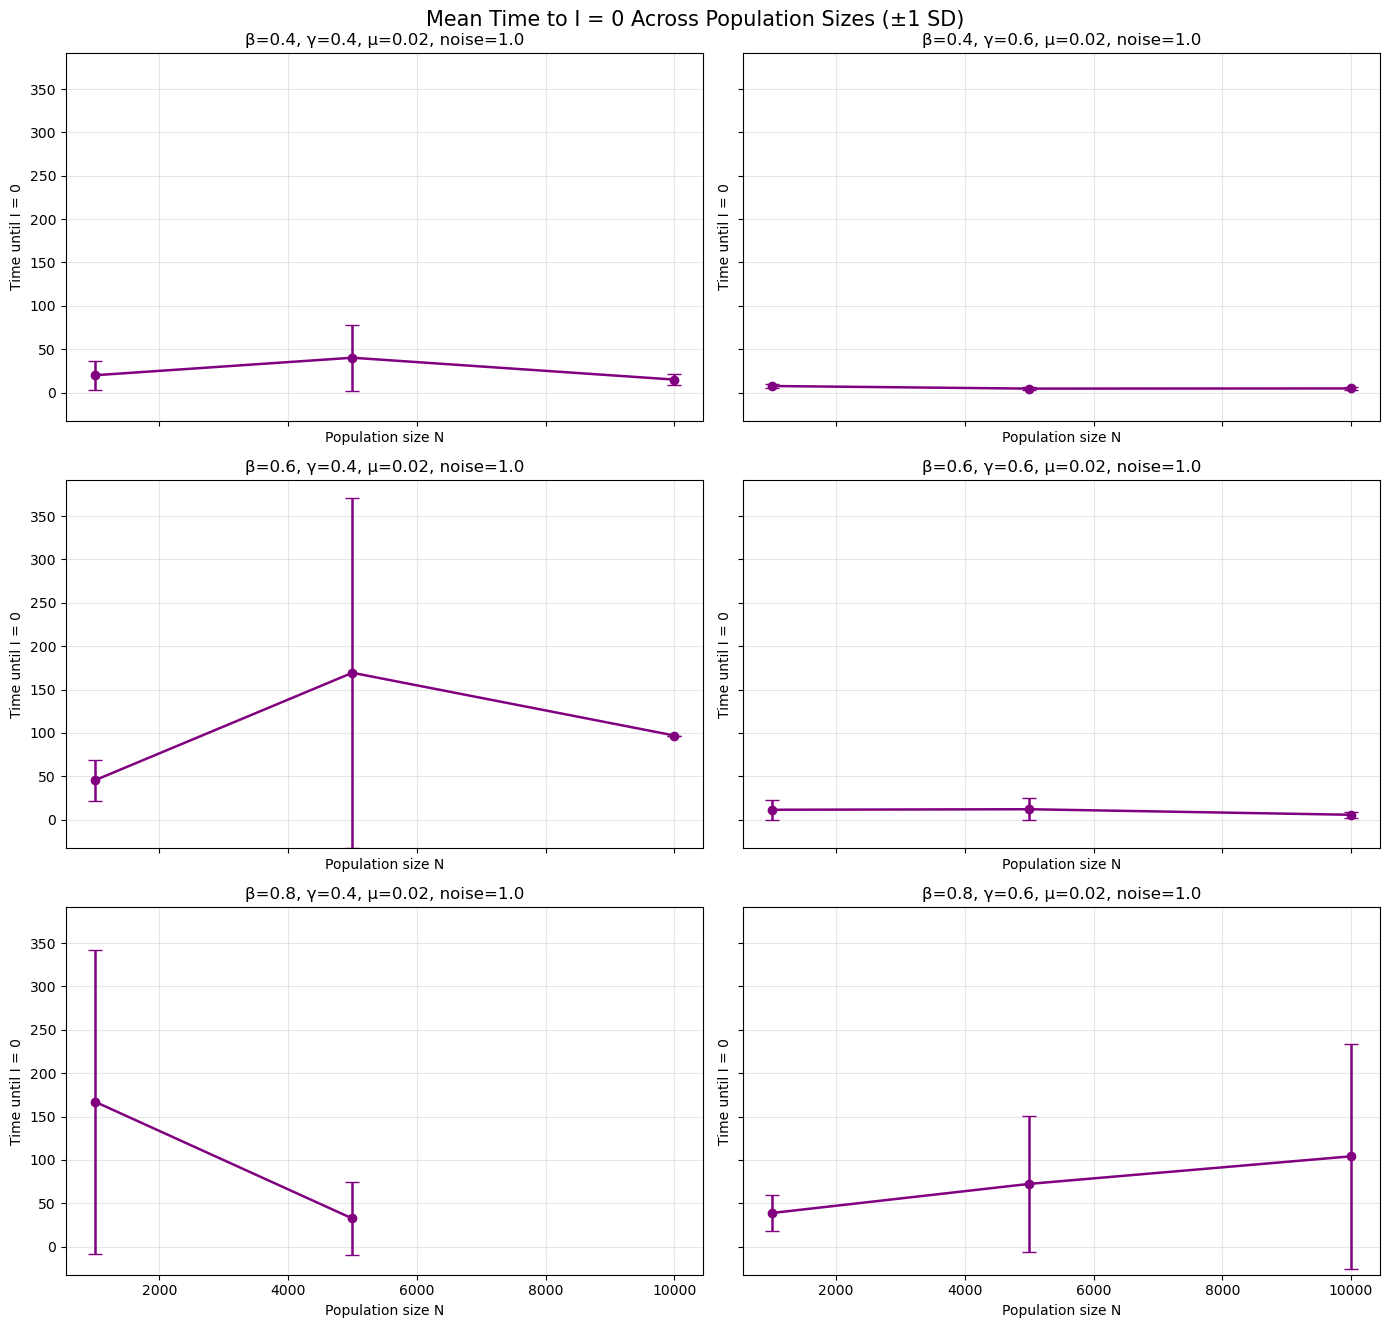

In [ ]:
#plot when runs went extinct
#CAREFUL this only includes the runs that actually went extinct, in the larger N, larger R0 runs, many didnt. how to plot both in one.....
parameter_cols = ["beta", "gamma", "mu", "noise"]

# Only runs that reached I = 0
extinct_runs = extinction_df[
    extinction_df["reached_zero"]
    & extinction_df["first_zero_time"].notna()
].copy()

summary_extinction = (
    extinct_runs
    .groupby(parameter_cols + ["N"])["first_zero_time"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

parameter_sets = (
    extinction_df[parameter_cols]
    .drop_duplicates()
    .sort_values(parameter_cols)
    .reset_index(drop=True)
)

n_params = len(parameter_sets)
ncols = 2
nrows = math.ceil(n_params / ncols)

# Shared y-axis across all subplots
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(7 * ncols, 4.5 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

# Global y-axis limits based on all mean +/- SD values
if not summary_extinction.empty:
    sd_all = summary_extinction["std"].fillna(0)

    y_min = min(
        0,
        (summary_extinction["mean"] - sd_all).min()
    )
    y_max = (
        summary_extinction["mean"] + sd_all
    ).max()

    margin = 0.05 * (y_max - y_min) if y_max > y_min else 1
    y_limits = (y_min, y_max + margin)

for idx, params in parameter_sets.iterrows():

    ax = axes[idx]

    mask = np.ones(len(summary_extinction), dtype=bool)

    for col in parameter_cols:
        mask &= summary_extinction[col].eq(params[col]).to_numpy()

    subset = summary_extinction.loc[mask].sort_values("N")

    if subset.empty:
        ax.text(
            0.5, 0.5,
            "No runs reached I = 0",
            ha="center", va="center",
            transform=ax.transAxes
        )
    else:
        sd = subset["std"].fillna(0)

        ax.errorbar(
            subset["N"],
            subset["mean"],
            yerr=sd,
            fmt="o-",
            color="purple",
            ecolor="purple",
            capsize=5,
            linewidth=1.8,
            markersize=6
        )

    ax.set_xlabel("Population size N")
    ax.set_ylabel("Time until I = 0")
    ax.set_title(
        f"β={params['beta']}, γ={params['gamma']}, "
        f"μ={params['mu']}, noise={params['noise']}"
    )
    ax.grid(True, alpha=0.3)

    # Identical y-axis limits on every subplot
    if not summary_extinction.empty:
        ax.set_ylim(y_limits)

# Remove unused axes
for idx in range(n_params, len(axes)):
    fig.delaxes(axes[idx])

fig.suptitle(
    "Mean Time to I = 0 Across Population Sizes (±1 SD)",
    fontsize=15
)

plt.tight_layout()
plt.show()


## code from ndlib guide

In [60]:
#simulate SIR on the networks


model = ep.SIRModel(g)
import json
#print(json.dumps(model.parameters, indent=2))
model.available_statuses
import ndlib.models.ModelConfig as mc

cfg = mc.Configuration()
cfg.add_model_parameter('beta', 0.001) # infection rate
cfg.add_model_parameter('gamma', 0.01) # recovery rate
#set initial states
cfg.add_model_parameter("percentage_infected", 0.01)
model.set_initial_status(cfg)

#simulation execution
iterations = model.iteration_bunch(200, node_status=True)
trends = model.build_trends(iterations)

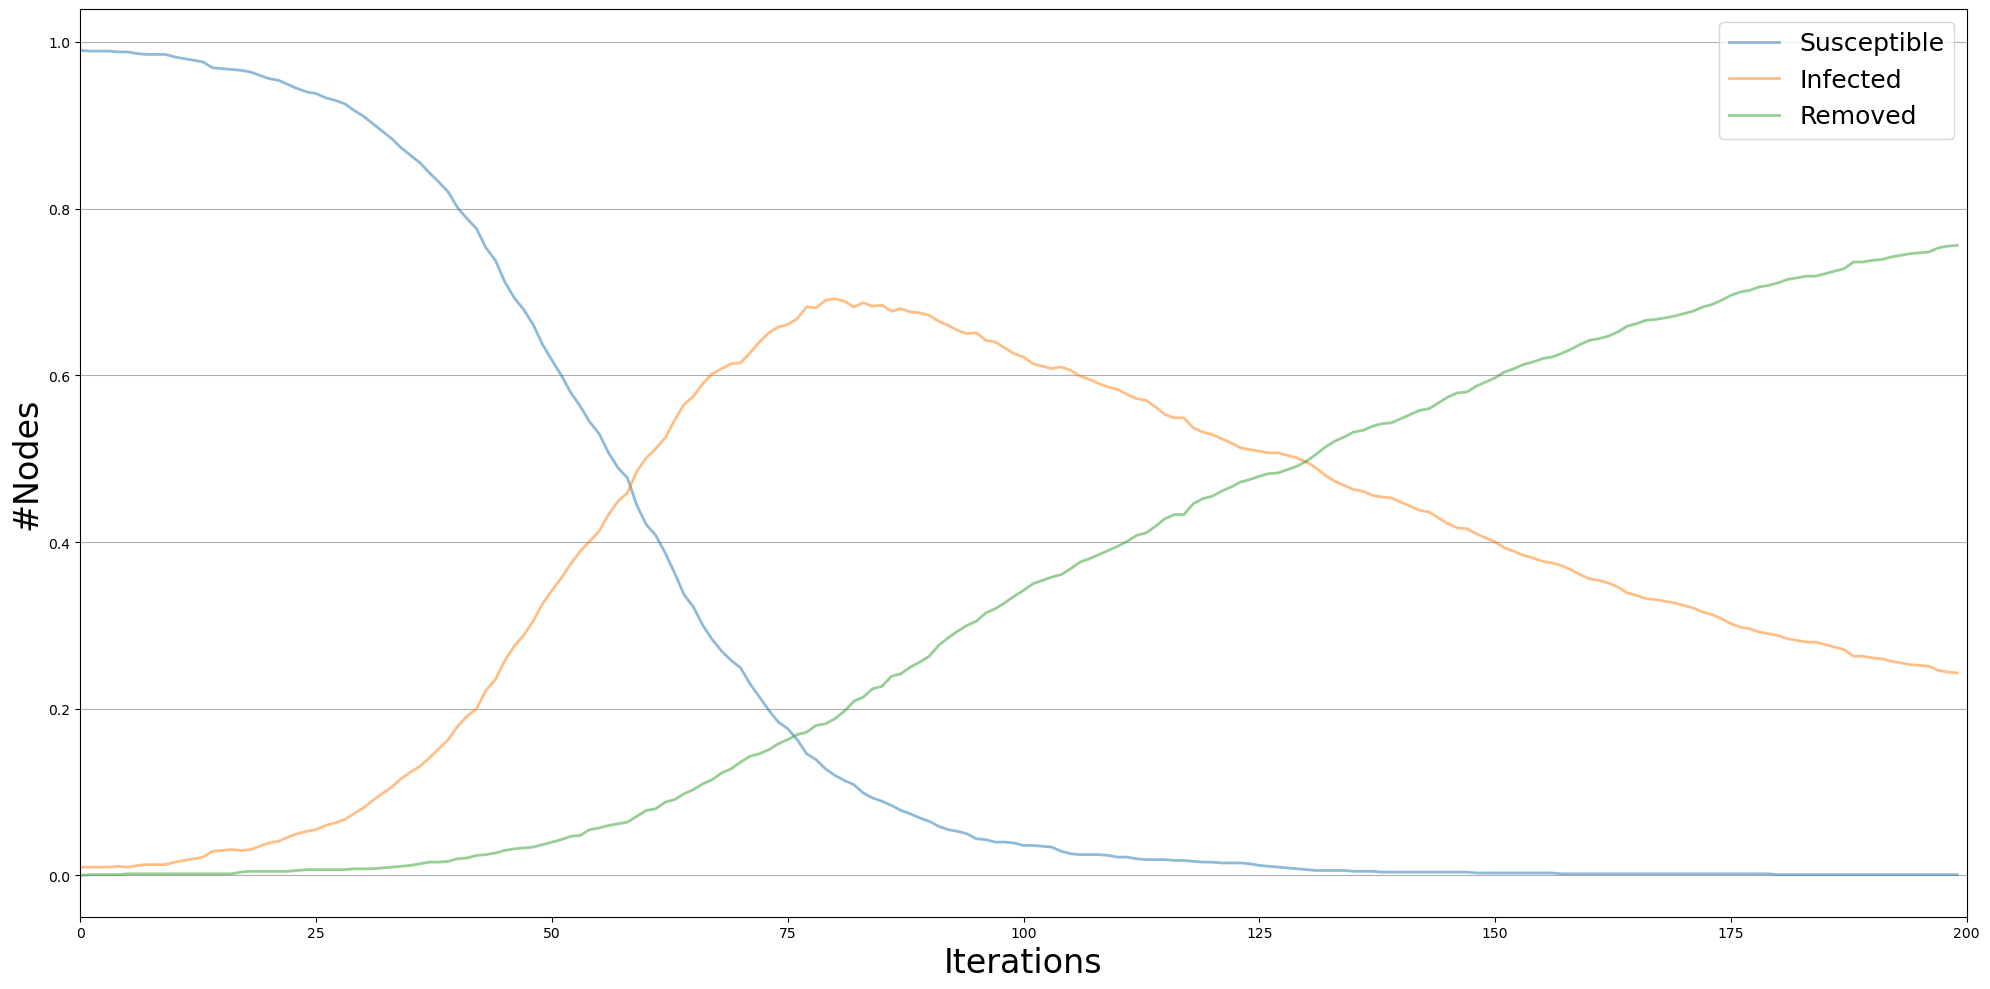

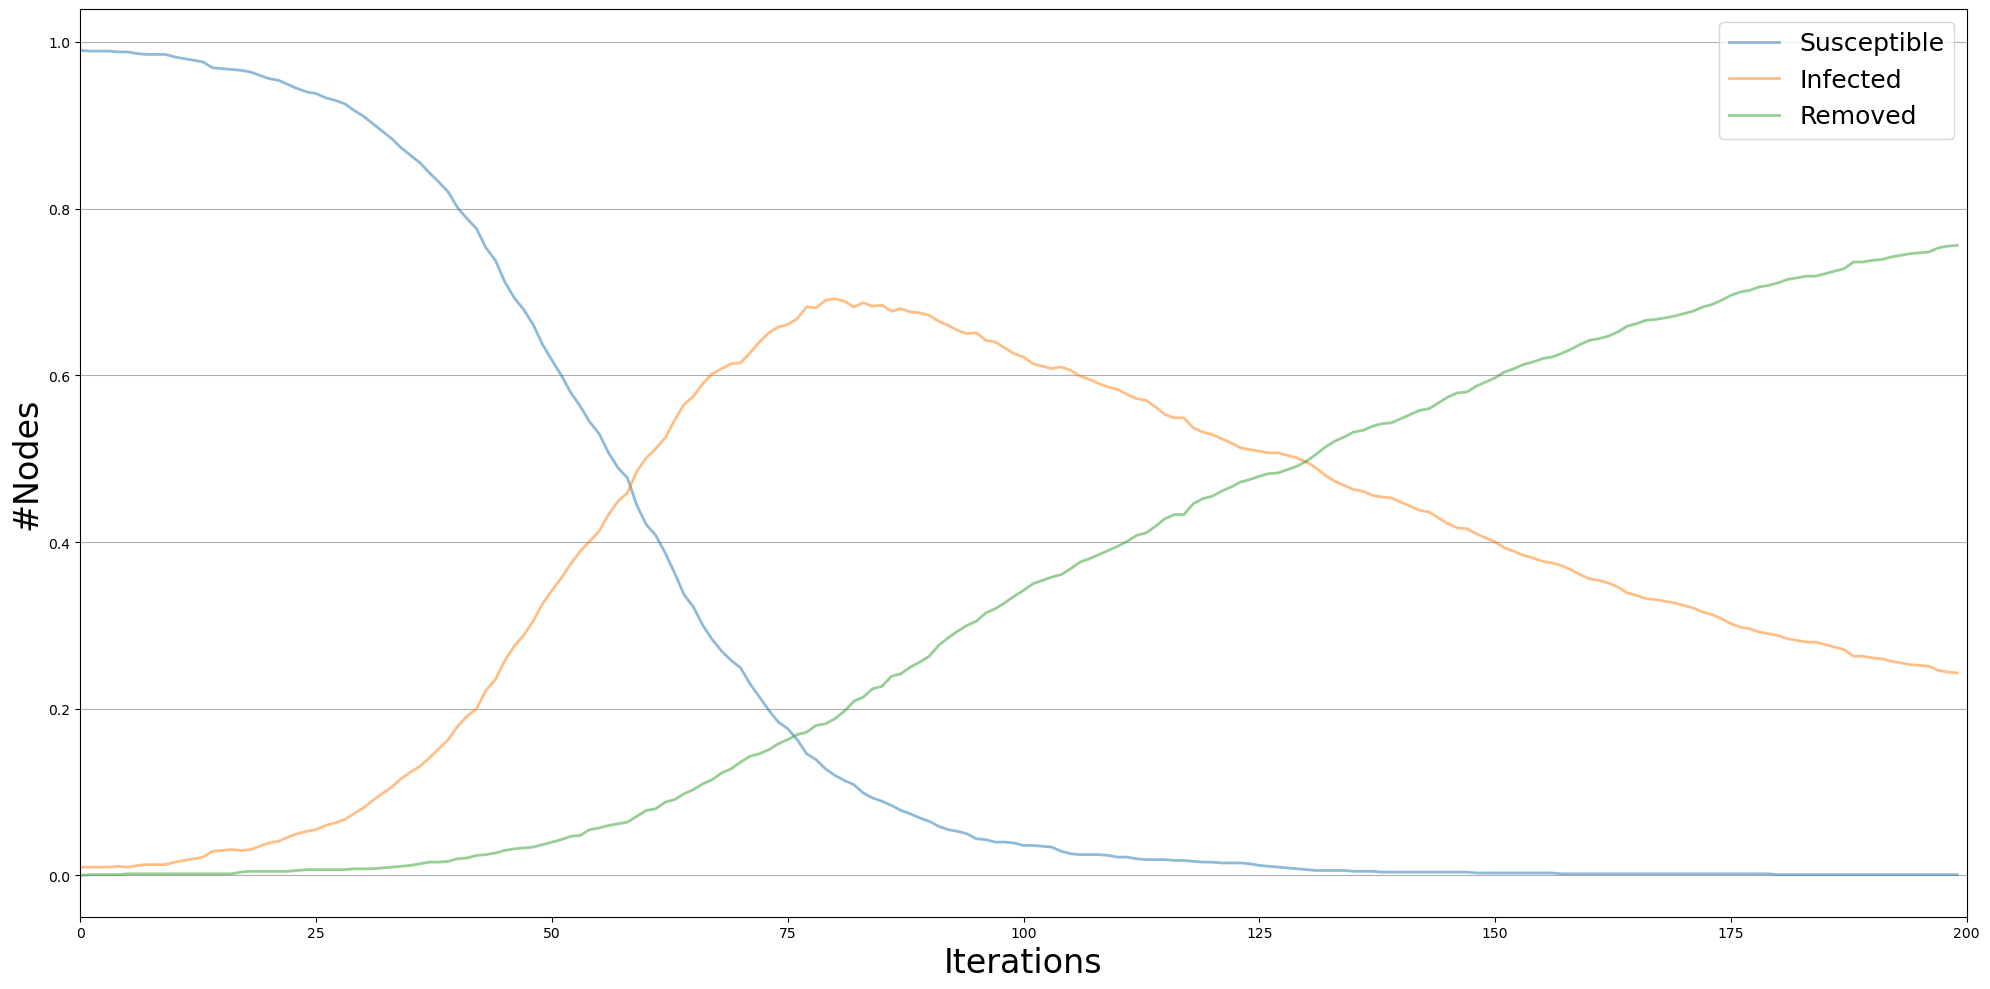

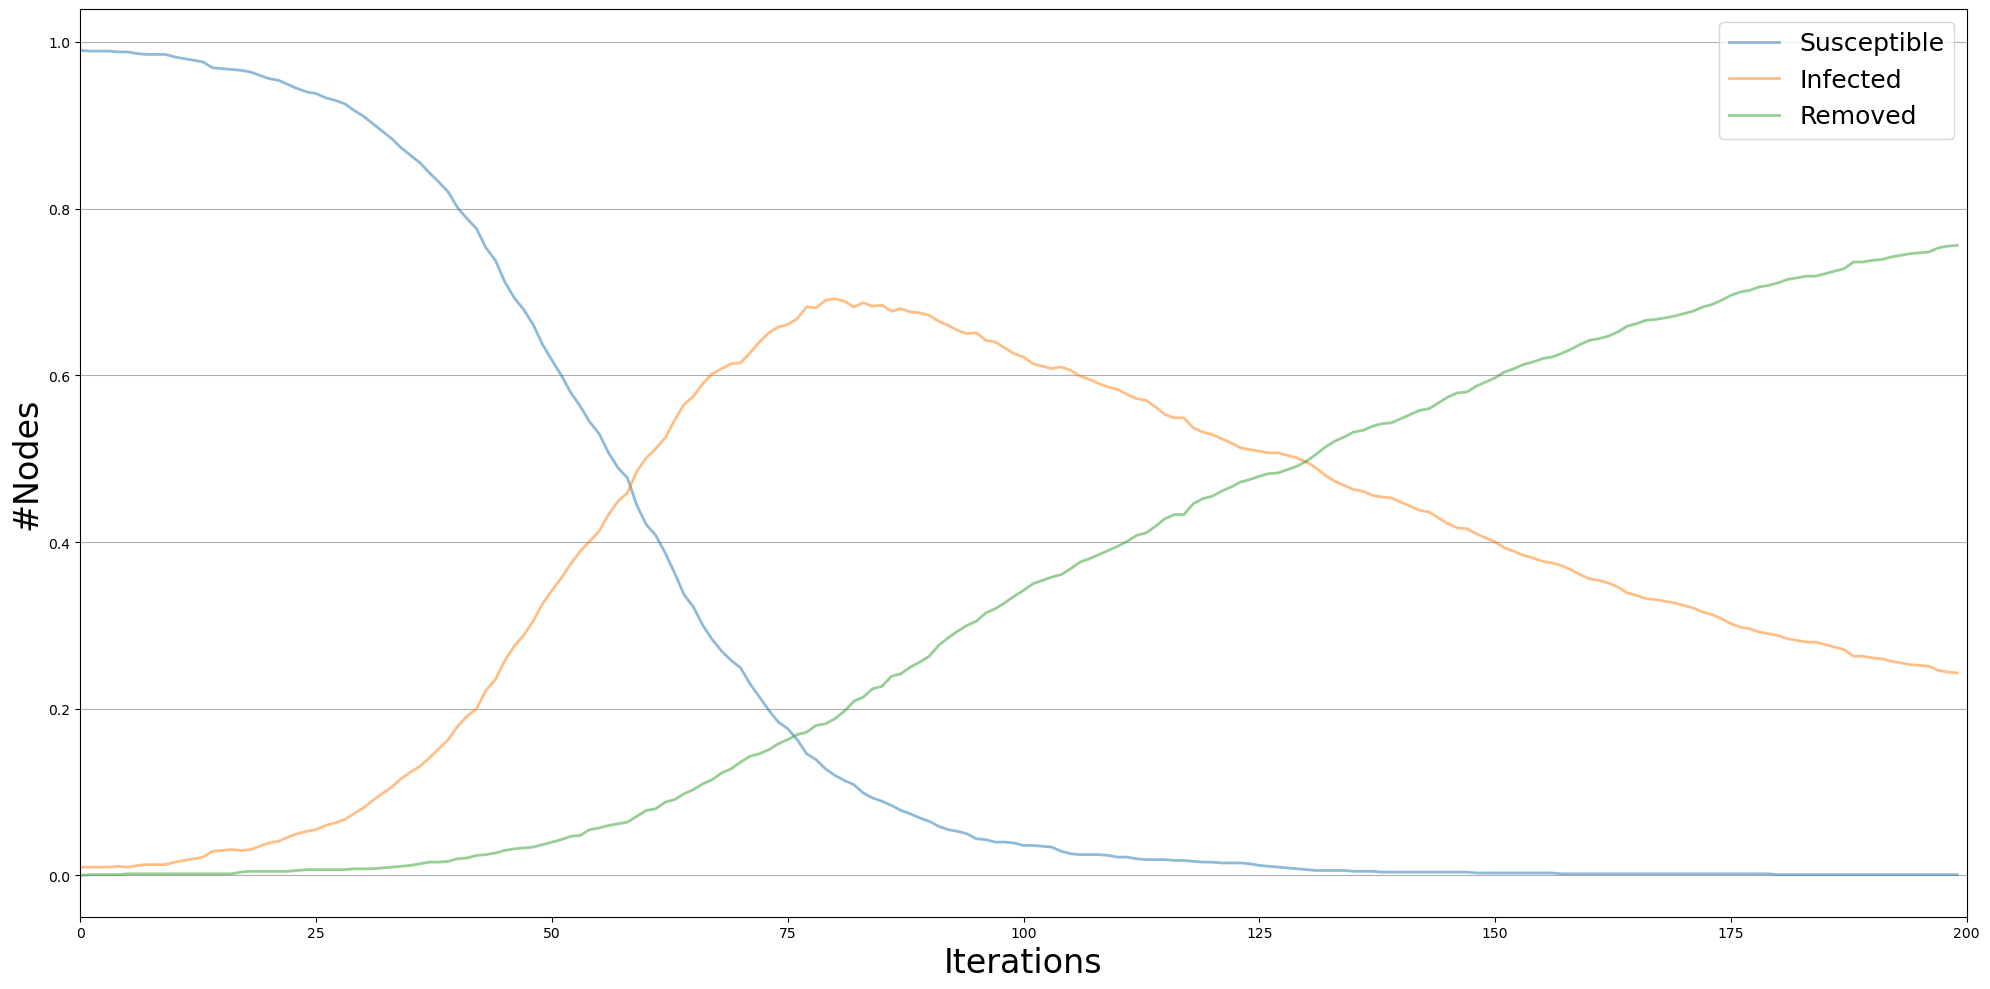

In [63]:
%matplotlib inline
from ndlib.viz.mpl.DiffusionTrend import DiffusionTrend
viz = DiffusionTrend(model, trends)
viz.plot()


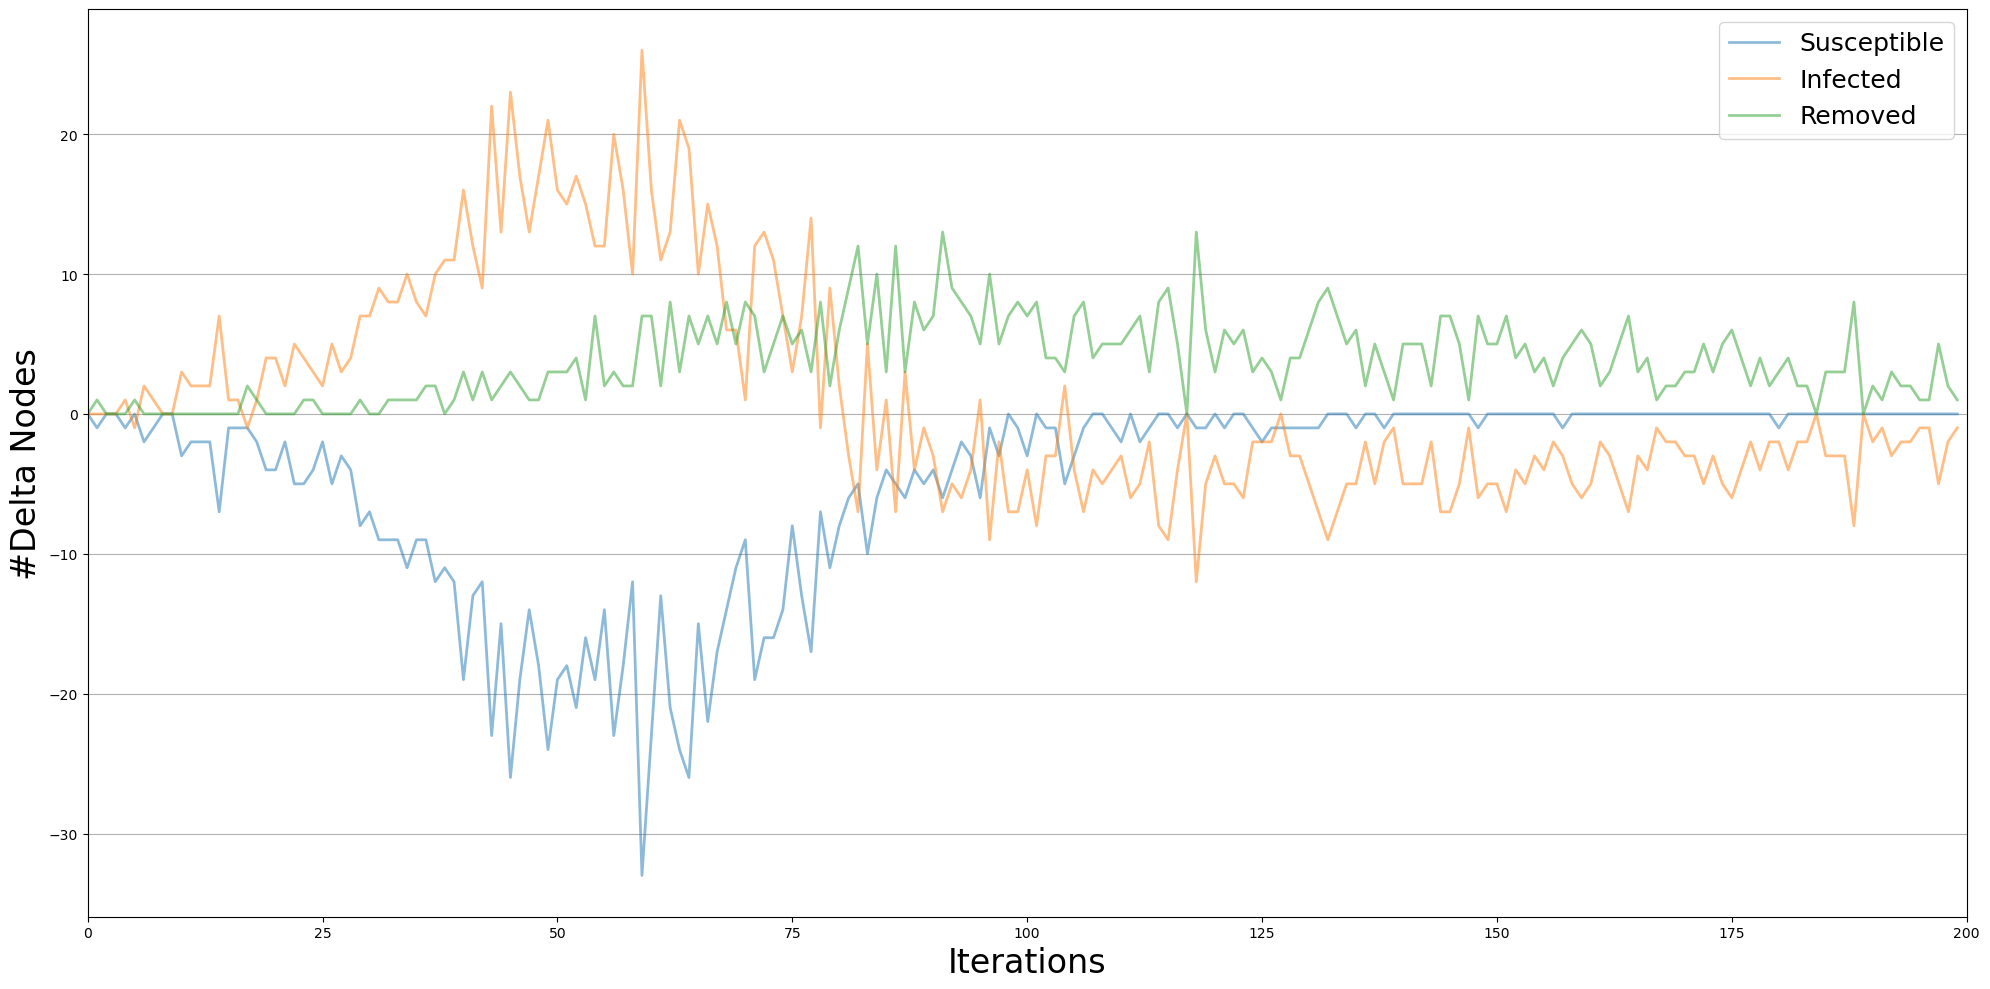

In [64]:
from ndlib.viz.mpl.DiffusionPrevalence import DiffusionPrevalence
viz = DiffusionPrevalence(model, trends)
viz.plot()

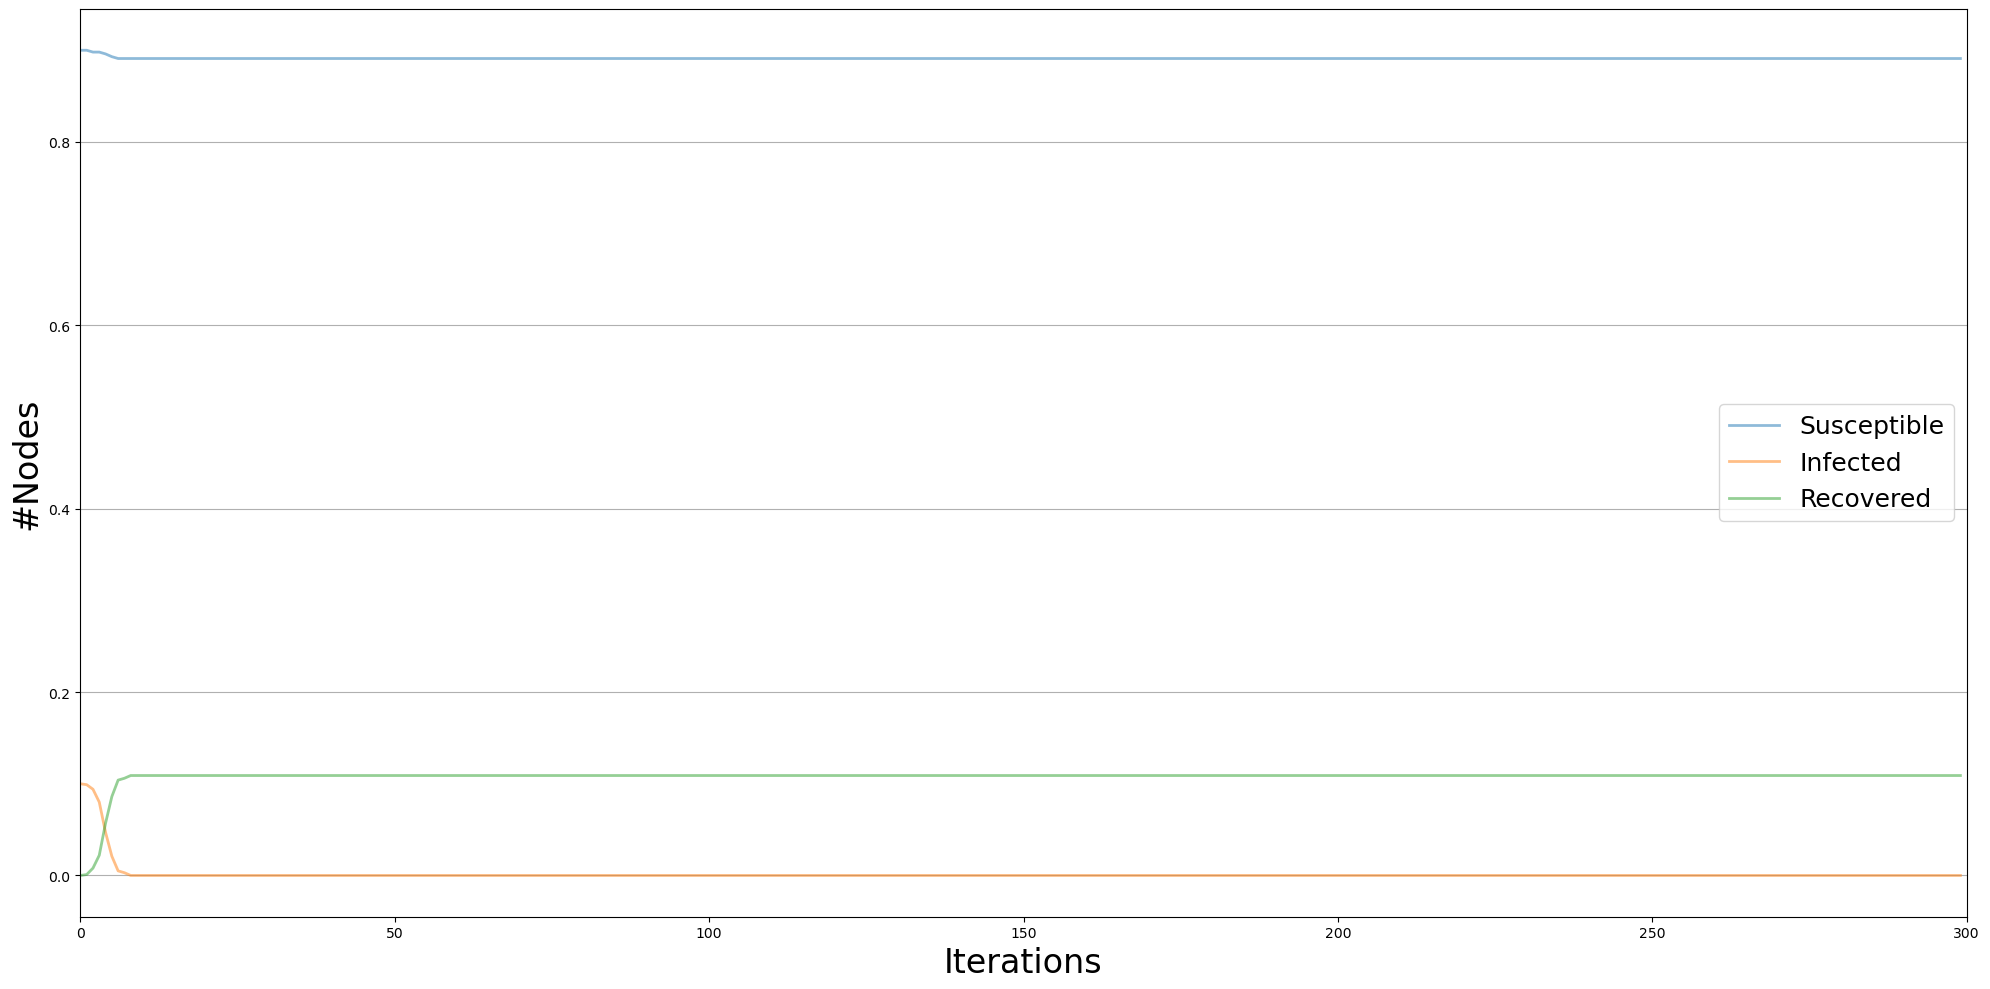

In [ ]:
#diy model - first sir then add vacc
import ndlib.models.CompositeModel as gc
import ndlib.models.compartments.NodeStochastic as ns

# Network generation
g = nx.erdos_renyi_graph(1000, 0.1)

# Composite Model instantiation
model = gc.CompositeModel(g)
model.add_status("Susceptible")
model.add_status("Infected")
model.add_status("Recovered")

import ndlib.models.compartments as ns #.NodeStochastic

#add stochastic rule: if at least 1 i neighbor, node will turn i with prob 0.02
# Compartments
c1 = ns.NodeStochastic(triggering_status='Infected', rate=0.001, probability=1)
c2 = ns.NodeStochastic(rate=0.01, probability=1)

# Rule definition
model.add_rule("Susceptible", "Infected", c1)
model.add_rule("Infected", "Recovered", c2)
#stochastic rule using edges: if direct edge between nnode and r, node will shift to r with prob 0.02
#-> use this for vacc?
import ndlib.models.compartments as es #.EdgeStochastic

c2 = es.EdgeStochastic(0.2, triggering_status="Recovered")

# Rule definition
model.add_rule("Infected", "Recovered", c2)

# add time varying rule for vacc?
# this rule shifts from i to r after 10 iteraton steps
import ndlib.models.compartments as cd #.CountDown

c3 = cd.CountDown("incubation", iterations=10)

# Rule definition
model.add_rule("Infected", "Recovered", c3)


# Model initial status configuration
config = mc.Configuration()
config.add_model_parameter('percentage_infected', 0.1)

# Simulation execution
model.set_initial_status(config)
iterations = model.iteration_bunch(300, node_status=False)
trends = model.build_trends(iterations)
viz = DiffusionTrend(model, trends)
viz.plot()

In [ ]:
#load dataset

design a dynamic vaccination strategy in which you have a testing budget and a limited number of vaccinations available per iteration of the model. Assume that you have a testing budget and a limited number of vaccinations available per iteration of the model.
Compare the strategies with different vaccination budgets of [1, 3, 5 and 10] per timestep and compare with different testing accuracy [0.5, 0.75, 1.0]

In [ ]:
#make null version which randomly assigns vaccinations

In [ ]:
#make vacc strategy, test on different values
#compare random vacc with the take node-vacc random partner strat 
#different strat that uses tests actively?